# Praktikum Minggu 10 — Cluster Analysis
Analisis negara berdasarkan rata-rata jumlah barang per transaksi menggunakan K-Means dan SSE. Jalankan cell berurutan. Jika library belum tersedia di kernel, jalankan `%pip install pandas numpy scikit-learn matplotlib` pada cell tambahan.

## Nomor 1 — Membaca dan menampilkan dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

dataset = pd.read_csv('transaction.csv')
print(dataset)
print('\nJumlah baris:', len(dataset))

       InvoiceNo  StockCode  ...  CustomerID               Country
0         537626      22725  ...       12347               Iceland
1         537626      22729  ...       12347               Iceland
2         537626      22195  ...       12347               Iceland
3         542237      22725  ...       12347               Iceland
4         542237      22729  ...       12347               Iceland
...          ...        ...  ...         ...                   ...
10541     543911      21700  ...       17829  United Arab Emirates
10542     543911      22111  ...       17829  United Arab Emirates
10543     543911      22112  ...       17829  United Arab Emirates
10544     564428      23296  ...       17844                Canada
10545     564428      23294  ...       17844                Canada

[10546 rows x 6 columns]

Jumlah baris: 10546


## Nomor 2 — Menghitung kemunculan setiap negara
Kemunculan adalah jumlah baris negara pada dataset.

In [2]:
country = dataset['Country'].value_counts()
print(country.to_string())
print('\nJumlah negara:', len(country))

Country
Germany                 2269
France                  2109
EIRE                    1620
Netherlands              634
Spain                    539
Belgium                  486
Switzerland              434
Portugal                 367
Australia                356
Norway                   239
Italy                    190
Channel Islands          184
Finland                  152
Cyprus                   113
Sweden                   109
Denmark                   98
Japan                     92
Austria                   88
Poland                    80
Israel                    61
USA                       47
Singapore                 45
Unspecified               44
Canada                    36
Iceland                   35
Greece                    33
United Arab Emirates      23
Malta                     15
RSA                       14
Lithuania                  8
Brazil                     8
European Community         5
Lebanon                    5
Czech Republic             4
Bahrai

## Nomor 3 — Rata-rata jumlah barang per transaksi tiap negara
Satu InvoiceNo dihitung sebagai satu transaksi pada setiap negara. Jumlahkan Qty seluruh baris invoice terlebih dahulu, lalu ambil rata-rata total Qty invoice per negara. Dengan demikian, rata-rata ini sama dengan total Qty negara dibagi jumlah invoice uniknya. Nilai Qty digunakan sesuai dataset.

In [3]:
assert dataset[['Country', 'InvoiceNo', 'Qty']].notna().all().all()
qty_per_invoice = dataset.groupby(['Country', 'InvoiceNo'])['Qty'].sum()
transaksi = pd.DataFrame(
    qty_per_invoice.groupby(level='Country').mean()
).rename(columns={'Qty': 'Rata-rata Qty per Transaksi'})

print(transaksi.to_string())

                      Rata-rata Qty per Transaksi
Country                                          
Australia                             4026.295455
Austria                               3420.250000
Bahrain                               1470.000000
Belgium                               3032.714286
Brazil                                4389.000000
Canada                                6449.666667
Channel Islands                       4569.714286
Cyprus                                3550.875000
Czech Republic                        1239.500000
Denmark                               3018.888889
EIRE                                  3788.866071
European Community                     921.666667
Finland                               3118.000000
France                                3197.549419
Germany                               3119.766578
Greece                                3473.000000
Iceland                               3267.666667
Israel                                7046.500000


## Nomor 4 — K-Means k=3 sebanyak 10 kali dan analisis SSE
Setiap percobaan menggunakan `init="random"`, `n_init=1`, dan seed berbeda (0–9) agar benar-benar ada sepuluh inisialisasi yang dapat diulang. SSE adalah jumlah kuadrat jarak setiap negara ke centroid clusternya. Fitur yang digunakan hanya rata-rata Qty per transaksi, tanpa normalisasi.

In [4]:
X = transaksi[['Rata-rata Qty per Transaksi']].to_numpy()
cluster_i = {}
cluster_val = {}
catatan_sse = []

for percobaan in range(1, 11):
    model = KMeans(n_clusters=3, init='random', n_init=1,
                   random_state=percobaan - 1)
    cluster_i[percobaan] = model.fit_predict(X)
    cluster_val[percobaan] = float(model.inertia_)
    catatan_sse.append({
        'Percobaan': percobaan,
        'Seed': percobaan - 1,
        'SSE': cluster_val[percobaan]
    })
    print(f'Percobaan {percobaan}:')
    print('Cluster:', cluster_i[percobaan])
    print(f'SSE: {cluster_val[percobaan]:.6f}')

hasil_sse = pd.DataFrame(catatan_sse)
print('\nRingkasan SSE:')
print(hasil_sse.to_string(index=False))

Percobaan 1:
Cluster: [1 1 2 1 1 0 1 1 2 1 1 2 1 1 1 1 1 0 1 1 1 2 1 1 1 1 1 0 2 0 1 2 0 0 0 1]
SSE: 13229107.198522
Percobaan 2:
Cluster: [0 0 1 0 0 2 0 0 1 0 0 1 0 0 0 0 0 2 0 0 0 1 0 0 0 0 0 2 1 2 0 1 2 2 2 0]
SSE: 13229107.198522
Percobaan 3:
Cluster: [0 0 2 0 0 1 0 0 2 0 0 2 0 0 0 0 0 1 0 0 0 2 0 0 0 0 0 1 2 1 0 2 1 1 1 0]
SSE: 13229107.198522
Percobaan 4:
Cluster: [0 0 1 0 0 2 0 0 1 0 0 1 0 0 0 0 0 2 0 0 0 1 0 0 0 0 0 2 1 2 0 1 2 2 2 0]
SSE: 13229107.198522
Percobaan 5:
Cluster: [1 1 2 1 1 0 1 1 2 1 1 2 1 1 1 1 1 0 1 1 1 2 1 1 1 2 1 0 2 0 1 2 0 0 0 1]
SSE: 13246218.620888
Percobaan 6:
Cluster: [0 0 1 0 0 2 0 0 1 0 0 1 0 0 0 0 0 2 0 0 0 1 0 0 0 0 0 2 1 2 0 1 2 2 2 0]
SSE: 13229107.198522
Percobaan 7:
Cluster: [0 0 1 1 0 2 0 0 1 1 0 1 1 1 1 0 1 2 1 1 1 1 0 0 0 1 0 2 1 2 0 1 2 0 2 1]
SSE: 16420994.708163
Percobaan 8:
Cluster: [0 0 1 0 0 2 0 0 1 0 0 1 0 0 0 0 0 2 0 0 0 1 0 0 0 0 0 2 1 2 0 1 2 2 2 0]
SSE: 13229107.198522
Percobaan 9:
Cluster: [2 2 0 2 2 1 2 2 0 2 2 0 2 2 2 2 2 1 2 2 2

## Nomor 5 — Memilih hasil clustering dengan SSE terkecil
Jika SSE minimum sama persis pada beberapa percobaan, pilih percobaan pertama yang mencapainya. Ini adalah hasil terbaik di antara sepuluh percobaan yang dijalankan.

In [5]:
percobaan_terbaik = min(cluster_val, key=lambda i: cluster_val[i])
cluster = cluster_i[percobaan_terbaik].copy()
transaksi['Cluster'] = cluster

print('Percobaan terpilih:', percobaan_terbaik)
print(f'SSE terkecil: {cluster_val[percobaan_terbaik]:.6f}')
print(transaksi.to_string())

Percobaan terpilih: 1
SSE terkecil: 13229107.198522
                      Rata-rata Qty per Transaksi  Cluster
Country                                                   
Australia                             4026.295455        1
Austria                               3420.250000        1
Bahrain                               1470.000000        2
Belgium                               3032.714286        1
Brazil                                4389.000000        1
Canada                                6449.666667        0
Channel Islands                       4569.714286        1
Cyprus                                3550.875000        1
Czech Republic                        1239.500000        2
Denmark                               3018.888889        1
EIRE                                  3788.866071        1
European Community                     921.666667        2
Finland                               3118.000000        1
France                                3197.549419        1
Germ

## Nomor 6 — Menghitung centroid setiap cluster
Centroid merupakan rata-rata fitur negara-negara dalam cluster terpilih.

In [6]:
centroid = transaksi.groupby('Cluster')['Rata-rata Qty per Transaksi'].mean()
print(centroid.to_string())

Cluster
0    6173.850813
1    3542.219521
2    1400.130342


## Nomor 7 — Mengurutkan centroid secara ascending

In [7]:
centroid_sorted = centroid.sort_values()
print(centroid_sorted.to_string())

Cluster
2    1400.130342
1    3542.219521
0    6173.850813


## Nomor 8 — Menentukan kategori rendah, sedang, dan tinggi
Kategori mengikuti urutan centroid, bukan angka label cluster. Tingkat transaksi di sini merujuk pada rata-rata Qty per transaksi, bukan banyaknya invoice.

In [8]:
peta_kategori = dict(zip(centroid_sorted.index, ['Rendah', 'Sedang', 'Tinggi']))
transaksi['Kategori'] = transaksi['Cluster'].map(peta_kategori)

for tingkat in ['Rendah', 'Sedang', 'Tinggi']:
    anggota = transaksi.loc[transaksi['Kategori'] == tingkat]
    print(f'\nKategori {tingkat} ({len(anggota)} negara):')
    print(anggota.to_string())


Kategori Rendah (6 negara):
                    Rata-rata Qty per Transaksi  Cluster Kategori
Country                                                          
Bahrain                             1470.000000        2   Rendah
Czech Republic                      1239.500000        2   Rendah
European Community                   921.666667        2   Rendah
Lithuania                           2013.000000        2   Rendah
Saudi Arabia                         592.000000        2   Rendah
Sweden                              2164.615385        2   Rendah

Kategori Sedang (23 negara):
                 Rata-rata Qty per Transaksi  Cluster Kategori
Country                                                       
Australia                        4026.295455        1   Sedang
Austria                          3420.250000        1   Sedang
Belgium                          3032.714286        1   Sedang
Brazil                           4389.000000        1   Sedang
Channel Islands                  45

## Nomor 9 — Visualisasi hasil cluster
Sumbu X menunjukkan urutan negara dan sumbu Y menunjukkan rata-rata Qty per transaksi. Warna hijau, oranye, dan merah menunjukkan kategori rendah, sedang, dan tinggi.

Gambar tersimpan: cluster_week10.png
Tabel tersimpan: hasil_sse_week10.csv dan hasil_cluster_week10.csv


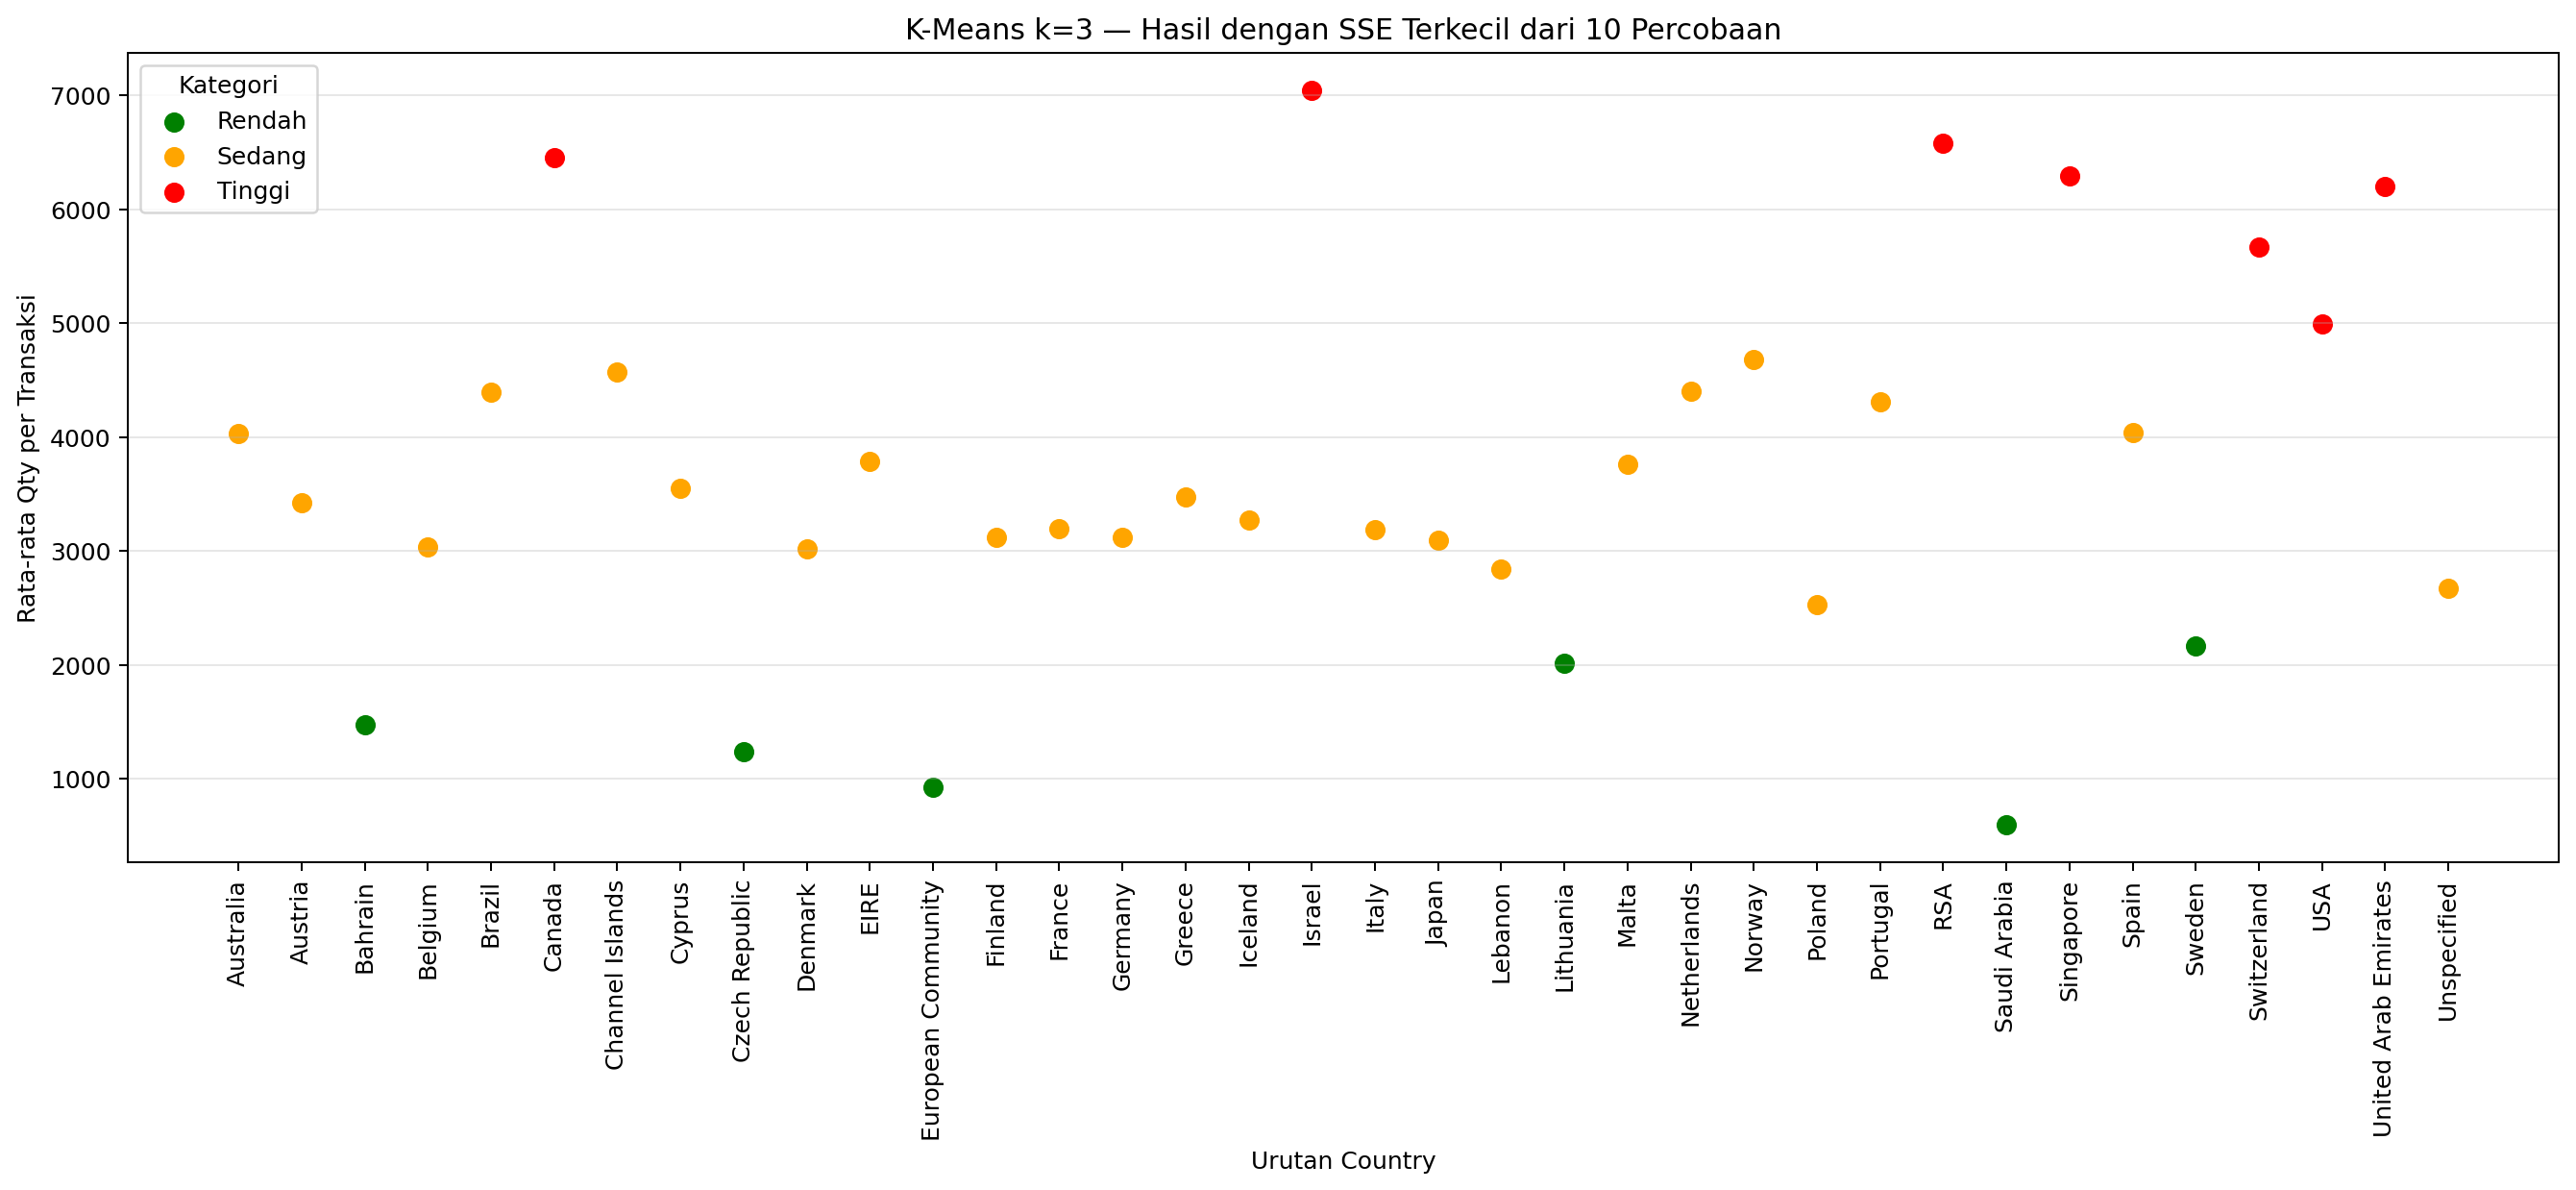

In [9]:
urutan_country = np.arange(len(transaksi))
nilai_transaksi = transaksi['Rata-rata Qty per Transaksi'].to_numpy()
kategori_negara = transaksi['Kategori'].to_numpy()
warna = {'Rendah': 'green', 'Sedang': 'orange', 'Tinggi': 'red'}

fig, ax = plt.subplots(figsize=(15, 7))
for tingkat, warna_cluster in warna.items():
    anggota = kategori_negara == tingkat
    ax.scatter(urutan_country[anggota], nilai_transaksi[anggota],
               color=warna_cluster, label=tingkat, s=55)

ax.set_xticks(urutan_country)
ax.set_xticklabels([str(negara) for negara in transaksi.index], rotation=90)
ax.set_xlabel('Urutan Country')
ax.set_ylabel('Rata-rata Qty per Transaksi')
ax.set_title('K-Means k=3 — Hasil dengan SSE Terkecil dari 10 Percobaan')
ax.legend(title='Kategori')
ax.grid(axis='y', alpha=0.3)
fig.tight_layout()
fig.savefig('cluster_week10.png', dpi=180, bbox_inches='tight')
plt.show()

hasil_sse.to_csv('hasil_sse_week10.csv', index=False)
transaksi.to_csv('hasil_cluster_week10.csv')
print('Gambar tersimpan: cluster_week10.png')
print('Tabel tersimpan: hasil_sse_week10.csv dan hasil_cluster_week10.csv')

## Kesimpulan
Praktikum ini mengelompokkan 36 negara berdasarkan rata-rata jumlah barang per transaksi menggunakan K-Means dengan k=3. Setelah sepuluh percobaan dengan inisialisasi berbeda, percobaan 1 dipilih karena memiliki SSE terkecil sebesar 13229107.198522. Pengurutan centroid menghasilkan kategori rendah sebanyak 6 negara, sedang sebanyak 23 negara, dan tinggi sebanyak 7 negara. Visualisasi memperlihatkan perbedaan rata-rata Qty per transaksi antarnegara. SSE membantu memilih hasil yang lebih kompak di antara percobaan dengan fitur dan jumlah cluster yang sama.